In [1]:
# --------- 1 ------------


import numpy as np
import pandas as pd

from xgboost import XGBRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.model_selection import KFold

In [2]:
# ---------- 2 ------------

df = pd.read_parquet("training_dataset_Arabian_Sea_clean.parquet")

# -----------------------------
# Western Arabian Sea
# Lon: 45°E–65°E
# Lat: 5°N–28°N
# -----------------------------

df = df[
    (df["longitude"] >= 45) &
    (df["longitude"] <= 65) &
    (df["latitude"]  >= 5) &
    (df["latitude"]  <= 28)
].copy()

print(f"Total samples in Western Arabian Sea = {len(df):,}")

TARGET = "chlor_a_log10"

DROP_COLS = [
    TARGET,
    "latitude",
    "longitude",
    "year",
    "month",
    "zos",
    "grad_ssh"
]

# -----------------------------
# Train : 1998-2024
# Test  : 2025
# -----------------------------

train_df = df[
    (df["year"] >= 1998) &
    (df["year"] <= 2024)
].copy()

test_df = df[
    df["year"] == 2025
].copy()

train_df = train_df.sort_values(
    ["year", "month"]
).reset_index(drop=True)

test_df = test_df.sort_values(
    ["year", "month"]
).reset_index(drop=True)

FEATURES = [
    col for col in df.columns
    if col not in DROP_COLS
]

X_train = train_df[FEATURES].astype("float32")
y_train = train_df[TARGET].astype("float32")

X_test = test_df[FEATURES].astype("float32")
y_test = test_df[TARGET].astype("float32")

print(f"Training samples : {len(X_train):,}")
print(f"Testing samples  : {len(X_test):,}")
print(f"Number of features : {len(FEATURES)}")

Total samples in Western Arabian Sea = 12,277,848
Training samples : 11,717,175
Testing samples  : 449,711
Number of features : 9


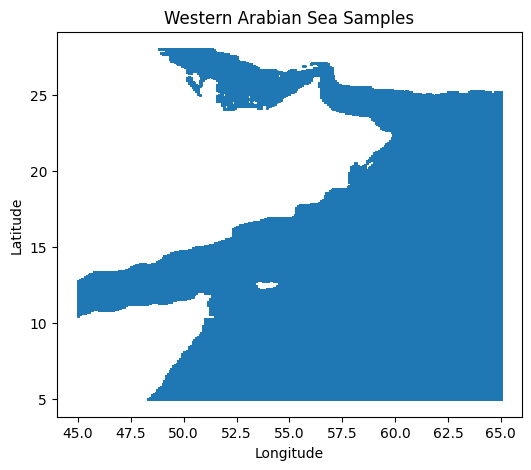

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.scatter(
    df["longitude"],
    df["latitude"],
    s=0.1,
    alpha=0.2
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Western Arabian Sea Samples")
plt.show()

In [4]:

print(train_df.shape)
print(test_df.shape)



(11717175, 16)
(449711, 16)


In [5]:
# --------- 3 --------------

# ============================================================
# Standard K-Fold Cross Validation
# ============================================================

kf = KFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

fold_indices = list(kf.split(X_train))

# ============================================================
# Check Folds
# ============================================================

for i, (train_idx, valid_idx) in enumerate(fold_indices, start=1):

    print(f"\nFold {i}")

    print(
        f"Train Samples: {len(train_idx):,}"
    )

    print(
        f"Valid Samples: {len(valid_idx):,}"
    )


Fold 1
Train Samples: 5,858,587
Valid Samples: 5,858,588

Fold 2
Train Samples: 5,858,588
Valid Samples: 5,858,587


In [6]:
UNDER_PENALTY = 2.8

def underestimation_loss(y_true, y_pred):

    error = y_true - y_pred

    under_mask = error > 0

    grad = np.where(
        under_mask,
        -2.0 * (1.0 + UNDER_PENALTY) * error,
        -2.0 * error
    )

    hess = np.where(
        under_mask,
        2.0 * (1.0 + UNDER_PENALTY),
        2.0
    )

    return grad, hess

In [7]:
# ------------ 7 ---------------

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

#Trial 1 finished with value: 0.13319054245948792 and parameters: {'max_depth': 29, 'n_estimators': 506, 'learning_rate': 0.1644842504860716, 'subsample': 0.986622132040021, 'colsample_bytree': 0.9133573021746104, 'min_child_weight': 55, 'gamma': 3.056766313794807, 'reg_alpha': 0.023850492624993, 'reg_lambda': 72.03274016830103}. Best is trial 1 with value: 0.13319054245948792.


#{'n_estimators': 749, 'max_depth': 30, 'learning_rate': 0.025999207032918647, 'subsample': 0.9814517181045628, 'colsample_bytree': 0.9376012346867608, 'min_child_weight': 56, 'gamma': 2.801031229013032, 'reg_alpha': 0.07877116651640402, 'reg_lambda': 64.74612523782861}


best_model_params = {

    "max_depth":16,
    "n_estimators":664,
    "learning_rate":0.025366 ,
    "subsample":  0.958074 ,
    "colsample_bytree":0.930317,
    "min_child_weight":59,
    "gamma":3.434567,
    "reg_alpha":0.142527,
    "reg_lambda":74.930500
}


results = []

for fold, (train_idx, valid_idx) in enumerate(
    fold_indices,
    start=1
):

    X_tr = X_train.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]

    X_val = X_train.iloc[valid_idx]
    y_val = y_train.iloc[valid_idx]

    model = XGBRegressor(
        objective=underestimation_loss,
        tree_method="gpu_hist",
        predictor="gpu_predictor",
        random_state=42,
        n_jobs=-1,
        **best_model_params
    )
    model.fit(
    X_tr,
    y_tr,
    verbose=False
    )
    
    
    

    

    

    # ----------------------------------                 # Train- val metrics 
    # Train Metrics
    # ----------------------------------

    pred_train = model.predict(X_tr)

    train_r2 = r2_score(y_tr, pred_train)

    train_rmse = np.sqrt(
        mean_squared_error(y_tr, pred_train)
    )

    train_mae = mean_absolute_error(
        y_tr,
        pred_train
    )

    train_bias = np.mean(
        pred_train - y_tr
    )

    # ----------------------------------
    # Validation Metrics
    # ----------------------------------

    pred_val = model.predict(X_val)

    val_r2 = r2_score(y_val, pred_val)

    val_rmse = np.sqrt(
        mean_squared_error(y_val, pred_val)
    )

    val_mae = mean_absolute_error(
        y_val,
        pred_val
    )

    val_bias = np.mean(
        pred_val - y_val
    )

    print(f"\nFold {fold}")

    print(
        f"TRAIN      | "
        f"R²={train_r2:.5f} | "
        f"RMSE={train_rmse:.5f} | "
        f"MAE={train_mae:.5f} | "
        f"Bias={train_bias:.5f}"
    )

    print(
        f"VALIDATION | "
        f"R²={val_r2:.5f} | "
        f"RMSE={val_rmse:.5f} | "
        f"MAE={val_mae:.5f} | "
        f"Bias={val_bias:.5f}"
    )

    results.append([
        fold,
        train_r2,
        val_r2,
        train_rmse,
        val_rmse,
        train_mae,
        val_mae,
        train_bias,
        val_bias
    ])

cv_metrics_df = pd.DataFrame(
    results,
    columns=[
        "Fold",
        "Train_R2",
        "Val_R2",
        "Train_RMSE",
        "Val_RMSE",
        "Train_MAE",
        "Val_MAE",
        "Train_Bias",
        "Val_Bias"
    ]
)

print("\n")
print(cv_metrics_df)


summary_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ]
})

print(summary_df)


# ============================================================
# CV Mean ± Std Summary
# ============================================================

cv_stats_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Train_SD": [

        cv_metrics_df["Train_R2"].std(),
        cv_metrics_df["Train_RMSE"].std(),
        cv_metrics_df["Train_MAE"].std(),
        cv_metrics_df["Train_Bias"].std()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ],

    "Validation_SD": [

        cv_metrics_df["Val_R2"].std(),
        cv_metrics_df["Val_RMSE"].std(),
        cv_metrics_df["Val_MAE"].std(),
        cv_metrics_df["Val_Bias"].std()
    ]
})

print("\nCross-Validation Mean ± SD")
print(cv_stats_df)


Fold 1
TRAIN      | R²=0.78510 | RMSE=0.15187 | MAE=0.11382 | Bias=0.06640
VALIDATION | R²=0.77702 | RMSE=0.15468 | MAE=0.11531 | Bias=0.06648

Fold 2
TRAIN      | R²=0.78423 | RMSE=0.15216 | MAE=0.11397 | Bias=0.06648
VALIDATION | R²=0.77740 | RMSE=0.15457 | MAE=0.11527 | Bias=0.06635


   Fold  Train_R2    Val_R2  Train_RMSE  Val_RMSE  Train_MAE   Val_MAE  \
0     1  0.785101  0.777025    0.151871  0.154684   0.113820  0.115308   
1     2  0.784229  0.777403    0.152165  0.154567   0.113971  0.115272   

   Train_Bias  Val_Bias  
0    0.066397  0.066481  
1    0.066484  0.066354  
  Metric  Train_Mean  Validation_Mean
0     R2    0.784665         0.777214
1   RMSE    0.152018         0.154626
2    MAE    0.113896         0.115290
3   Bias    0.066441         0.066417

Cross-Validation Mean ± SD
  Metric  Train_Mean  Train_SD  Validation_Mean  Validation_SD
0     R2    0.784665  0.000617         0.777214       0.000268
1   RMSE    0.152018  0.000208         0.154626       0.000083
2 

In [8]:
# --------------- 8 ------------------



final_model = XGBRegressor(
    objective=underestimation_loss,       
    tree_method="gpu_hist",
    predictor="gpu_predictor",
    random_state=42,
    n_jobs=-1,
    **best_model_params
)

final_model.fit(
    X_train,
    y_train,
    verbose=False
)

,objective,<function und...x7f2fd0c8f880>
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.930317
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,feature_types,None


In [9]:

# -----------------------------
# Train Predictions
# -----------------------------
y_train_pred = final_model.predict(X_train)

# -----------------------------
# Train Metrics
# -----------------------------
train_r2   = r2_score(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_mae  = mean_absolute_error(y_train, y_train_pred)
train_bias = np.mean(y_train_pred - y_train)

# -----------------------------
# Print Results
# -----------------------------
print("\n==============================")
print("Training Performance")
print("==============================")
print(f"Train R²   : {train_r2:.4f}")
print(f"Train RMSE : {train_rmse:.4f}")
print(f"Train MAE  : {train_mae:.4f}")
print(f"Train Bias : {train_bias:.4f}")


Training Performance
Train R²   : 0.8005
Train RMSE : 0.1463
Train MAE  : 0.1090
Train Bias : 0.0636


In [10]:
# ------------------ 9 ----------------------

import joblib

# ============================================================
# Save Final Model
# ============================================================

MODEL_PATH = "xgboost_WAS_No_SSH_model_10000.pkl"

joblib.dump(
    final_model,
    MODEL_PATH
)

print("\n" + "="*60)
print("MODEL SAVED SUCCESSFULLY")
print("="*60)
print(f"Saved as: {MODEL_PATH}")


MODEL SAVED SUCCESSFULLY
Saved as: xgboost_WAS_No_SSH_model_10000.pkl
